# 1. Initial setup
---
Installing dependencies and libraries as well as autoreloading modules and third-parties

In [21]:
# Installing dependencies for the analysis
%pip install pandas matplotlib openpyxl

Note: you may need to restart the kernel to use updated packages.


In [45]:
%reload_ext autoreload
%autoreload 2

# Importing all modules
import pandas as pd
import matplotlib as mlt
import matplotlib.pyplot as plt
import openpyxl as xl
from openpyxl import load_workbook
import math
from openpyxl.styles import PatternFill
from visualise import *

# Additional variables
SEVERITY = {
    'F8CBAD':'high', 
    'FEF802':'medium', 
    '92D050':'low', 
    'BDD7EE':'info', 
    'F60000':'critical', 
    '000000': None,
    'AEAAAA':'false_positives'
}

# 2. Data Cleaning
---

Clean the dataset to make sure the data points are consistent and accurate before proceeding. I guess it's a good practice to use `openpyxl` to make the cleaning process possible.

## I1 - Normalise all severity colors within the `New Bugs` sheet
Some of the cells possess a mismatch in color, such as using a theme/tint color. This can introduce difficulties comparing and evaluating severities later on.

In [78]:
PATH="Results.xlsx"
wb = load_workbook(PATH, data_only=True)
NBUGS = wb["New bugs"]

In [104]:
# Normalise the severity rating colors

RESULTS.iloc[1:33, 3:13].stack().unique()
for row in NBUGS.iter_rows(min_row=3, max_row=51, min_col=2, max_col=14):
    for cell in row:
        color = cell.fill.fgColor

        if (
            color.type == "theme"
            and color.theme == 5
            and abs((color.tint or 0) - 0.5999) < 0.0001
        ):
            cell.fill = PatternFill(fill_type="solid", fgColor="F8CBAD")

wb.save("Results.I1.xlsx")

# Ensuring that all colors are valid now
PATH="Results.I1.xlsx"
wb = load_workbook(PATH, data_only=True)
NBUGS = wb["New bugs"]
for row in NBUGS.iter_rows(min_row=3, max_row=51, min_col=2, max_col=14):
    for cell in row:
        color = cell.fill.fgColor
        if color.type=="theme":
            raise Exception("Invalid severity color")
        elif color.type=="rgb":
            colorRgb = color.rgb[2:]
            SEVERITY[colorRgb]
print("OK")

OK


## I2 - Lowercase all severities within the `Results` sheet.
Just to make everything consistent according to a common format, I will lowercase all severities and check for any malformed data points within the dataset

In [115]:
PATH="Results.I1.xlsx"

wb = load_workbook(PATH)
RESULTS = wb["Results"]

unique_values = set()

for row in RESULTS.iter_rows(min_row=2, max_row=33, min_col=4, max_col=13):
    for cell in row:
        # Lowercase hardcoded text only; leave formulas, numbers, colours, etc. unchanged
        if isinstance(cell.value, str):
            unique_values.add(cell.value.lower())
            cell.value = cell.value.lower()
            
wb.save("Results.Final.xlsx")
print(unique_values)

{'info', 'critical', 'low', 'high', 'medium'}


# 3. Data transformation
---
The section below is dedicated to transforming and converting the dataset into a collection of easily representative visualisations. The point is to construct sub-datasets suitable for the following purposes:

1. Efficiency evaluation between LLMs
2. Consistency evaluation between LLMs
3. Additional findings

# 4. Visualisation / Analysis
---
Extracting core details on what insights we can have and analyse from these visualisations between `Claude Opus 4.7`, `DeepSeek V4 Pro` and `Grok 4.6`.

## 4.1 Benchmark expected findings rate between LLMs
Which model performs best when it comes to finding intentional bugs and whether the severity rating is accurate.

> `QUESTION`: How many matched the severity rating, how many didn’t and how many missed the intended bugs ?

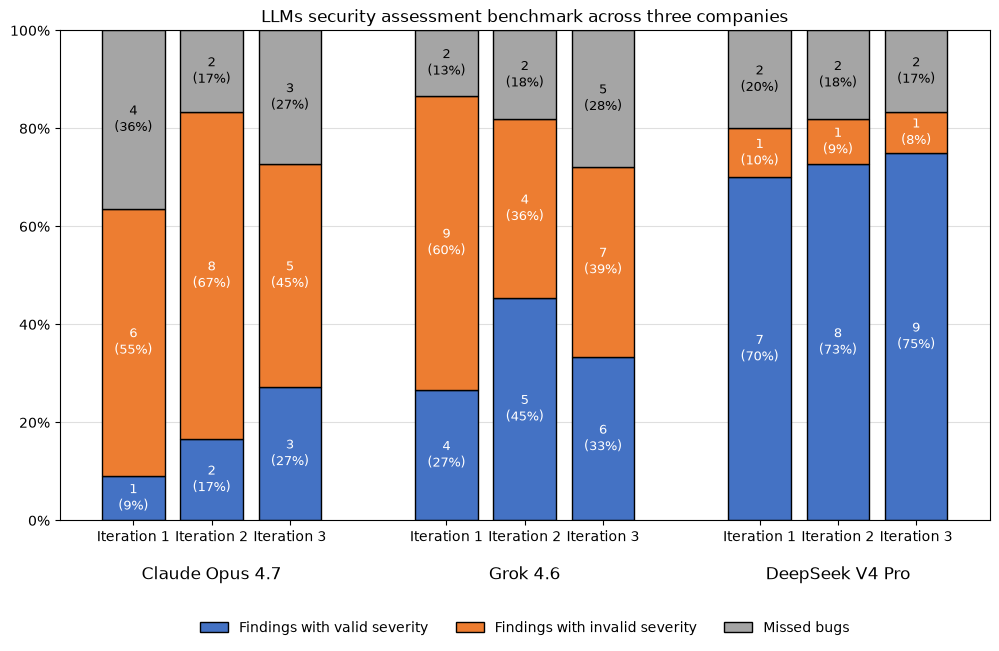

(<Figure size 1200x700 with 1 Axes>,
 <Axes: title={'center': 'LLMs security assessment benchmark across three companies'}>)

In [37]:
years = ["Claude Opus 4.7", "Grok 4.6", "DeepSeek V4 Pro"]
regions = ["Iteration 1", "Iteration 2", "Iteration 3"]

data = {
    "Findings with valid severity":  [1, 2, 3, 4, 5, 6,7,8,9],
    "Findings with invalid severity": [6, 8, 5, 9, 4, 7,1,1,1],
    "Missed bugs": [4, 2, 3, 2, 2, 5,2,2,2],
}

stacked_bar_groups_percent(
    years,
    regions,
    data,
    title="LLMs security assessment benchmark across three companies"
)

## 4.2 Benchmark the capabilities to discover new bugs between LLMs

Which model experiences the most false-positives / hallucinations, out-of-scoped items, bug uniqueness, and severity correctness.

> `QUESTION`: Across all overlapping bugs, which model possesses the highest rate of bug uniqueness across three flagship models. This means which one among them manages to discover bugs that are completely unique to the rest, where the other two models failed to discover such findings ? Additionally, talk about the severity of those bugs as well.

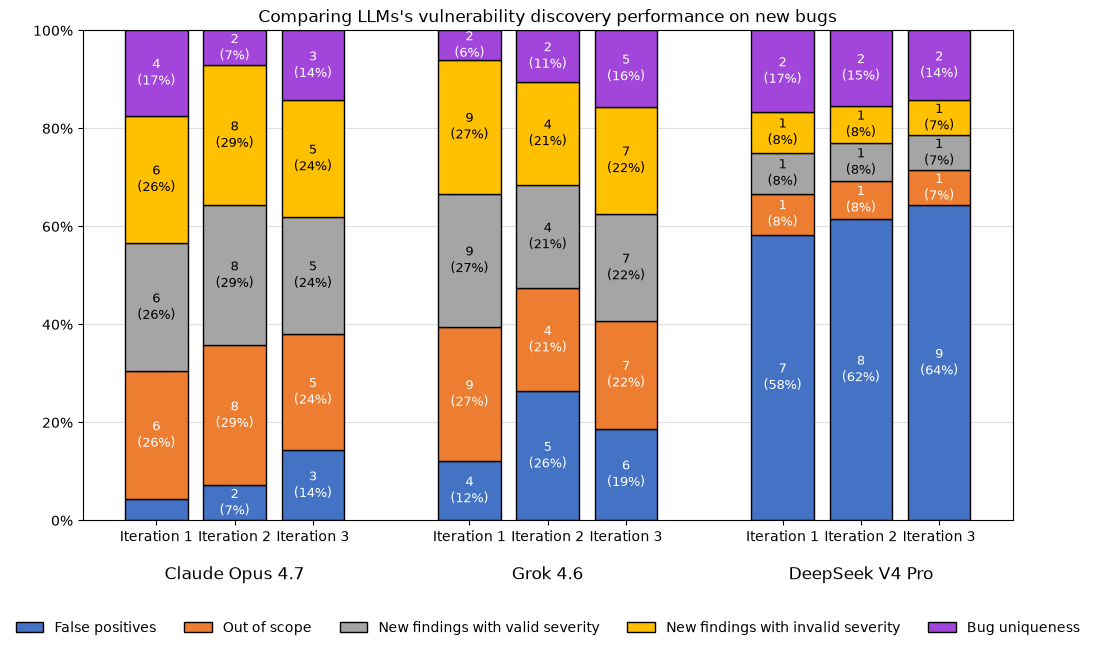

(<Figure size 1200x700 with 1 Axes>,
 <Axes: title={'center': "Comparing LLMs's vulnerability discovery performance on new bugs"}>)

In [36]:
years = ["Claude Opus 4.7", "Grok 4.6", "DeepSeek V4 Pro"]
regions = ["Iteration 1", "Iteration 2", "Iteration 3"]

data = {
    "False positives":  [1, 2, 3, 4, 5, 6,7,8,9],
    "Out of scope": [6, 8, 5, 9, 4, 7,1,1,1],
    "New findings with valid severity": [6, 8, 5, 9, 4, 7,1,1,1],
    "New findings with invalid severity": [6, 8, 5, 9, 4, 7,1,1,1],
    "Bug uniqueness": [4, 2, 3, 2, 2, 5,2,2,2],
}

stacked_bar_groups_percent(
    years,
    regions,
    data,
    title="Comparing LLMs's vulnerability discovery performance on new bugs"
)

## 4.2 Benchmark the cost between LLMs

Which model produces the cheapest cost overall, as well as the average cost ?

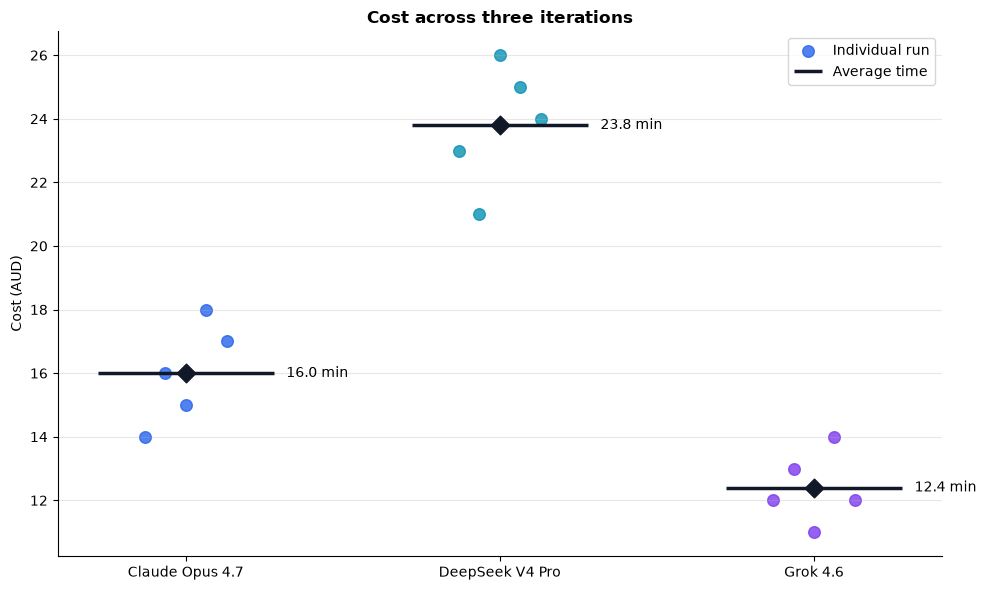

In [46]:
times = {
    "Claude Opus 4.7": [14, 16, 15, 18, 17],
    "DeepSeek V4 Pro": [23, 21, 26, 25, 24],
    "Grok 4.6": [12, 13, 11, 14, 12],
}

plot_dot_with_average(times, "Cost across three iterations", "Cost (AUD)")

## 4.2 Benchmark the time taken between three iterations per LLM

Which model takes the longest time to complete an assessment.

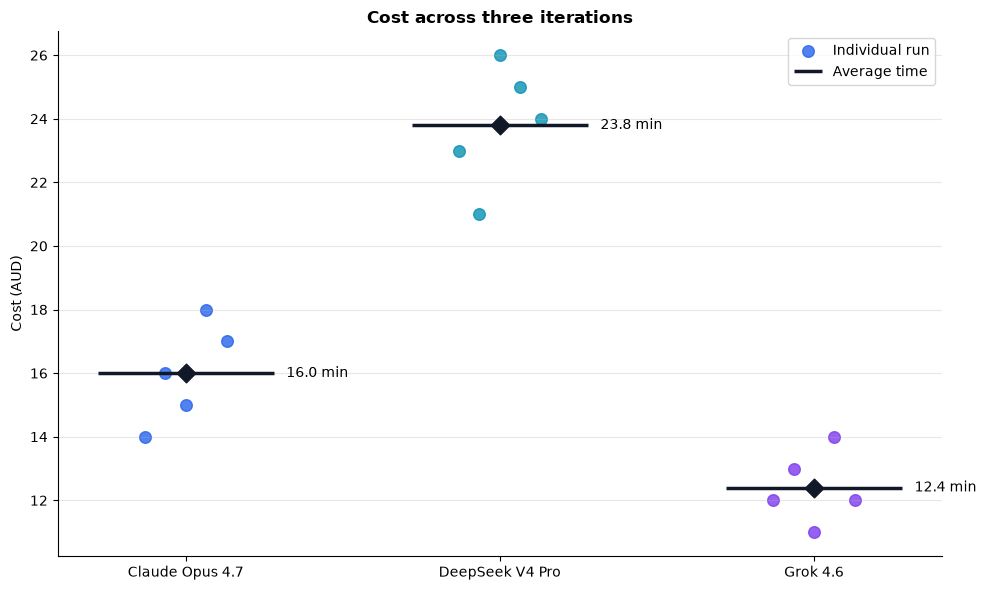

In [46]:
times = {
    "Claude Opus 4.7": [14, 16, 15, 18, 17],
    "DeepSeek V4 Pro": [23, 21, 26, 25, 24],
    "Grok 4.6": [12, 13, 11, 14, 12],
}

plot_dot_with_average(times, "Time taken across three iterations", "Time (minutes)")